# TRƯỜNG ĐẠI HỌC CÔNG NGHỆ THÔNG TIN - ĐHQG-HCM
### KHOA KHOA HỌC DỮ LIỆU & TRÍ TUỆ NHÂN TẠO
---
## HỌC PHẦN: DS200 - PHÂN TÍCH DỮ LIỆU LỚN (BIG DATA ANALYTICS)
### BÁO CÁO BÀI THỰC HÀNH BUỔI 3: PHÂN TÍCH DỮ LIỆU VÀ CÁC PHƯƠNG PHÁP HỌC CÓ GIÁM SÁT
## LAB 3.1: HỒI QUY TUYẾN TÍNH ĐƠN GIẢN (SIMPLE LINEAR REGRESSION)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/barackvn/MayHocNangCao/blob/main/Buoi3-Phan%20Tich%20Du%20lieu%20v%C3%A0%20Cac%20Phuong%20Phap%20hoc%20co%20giam%20s%C3%A1t/Lab3_1_HoiQuyTuyenTinhDonGian.ipynb)

* **Lớp:** DS200.G11.CN2.TTNT
* **Giảng viên hướng dẫn:** ThS. Hà Minh Tân
* **Sinh viên thực hiện:** Dương Quốc Thương
* **STT:** 66
* **Email:** hotro.76@gmail.com
* **Repository GitHub:** [https://github.com/barackvn/MayHocNangCao](https://github.com/barackvn/MayHocNangCao)
* **Nguồn dữ liệu gốc:** [Kaggle - Salary_data.csv](https://www.kaggle.com/datasets/ravitejakotharu/salary-datacsv)


---
## ❖ MÔ TẢ BÀI LAB & LÝ THUYẾT NỀN TẢNG

### 0.1 Simple Linear Regression - Hồi quy tuyến tính đơn giản

**Định nghĩa:**
* **Tiếng Việt:** Hồi quy tuyến tính đơn giản là tìm mối quan hệ tốt nhất giữa biến đầu vào $x$ (biến độc lập) và biến kỳ vọng $y$ (biến phụ thuộc). Mối quan hệ tuyến tính giữa hai biến này có thể được biểu diễn bằng một đường thẳng gọi là **đường hồi quy**.
* **English:** *Simple Linear Regression is finding the best relationship between the input variable $x$ (independent variable) and the expected variable $y$ (dependent variable). The linear relationship between these two variables can be represented by a straight line called regression line.*

**Công thức hồi quy tuyến tính:**
$$y = b_0 + b_1 x$$

**Các thuật ngữ biểu diễn:**
* $y$: là phản hồi hoặc biến mục tiêu (*response* hoặc *target variable* / biến phụ thuộc).
* $x$: là đặc điểm (*feature* hoặc *independent variable* / biến độc lập).
* $b_1$: là hệ số của $x$ (*coefficient* hoặc *slope* / hệ số góc).
* $b_0$: là giá trị cắt (*intercept* / hệ số chặn trên trục tung).

**Ước tính Hệ số Mô hình (“Học tập” - Estimating / Learning Model Coefficients):**
* Các hệ số được ước tính bằng cách sử dụng **tiêu chuẩn bình phương nhỏ nhất (Ordinary Least Squares - OLS)**. 
* Tức là, mô hình tính toán đường thẳng phù hợp nhất (*best fit line*) nhằm **tối thiểu hóa tổng bình phương phần dư** (hoặc *“tổng bình phương lỗi” - Sum of Squared Errors / Residual Sum of Squares - RSS*):
$$RSS = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 = \sum_{i=1}^{n} (y_i - (b_0 + b_1 x_i))^2 \to \min$$

---
### 0.2 Quy trình thực hiện (Dividing the code into steps)
1. **Bước 1 (Step 1):** Tải và chuẩn bị tập dữ liệu (*Load Dataset & Split Data*).
2. **Bước 2 (Step 2):** Trực quan hóa dữ liệu (*Visualize the data*).
3. **Bước 3 (Step 3):** Huấn luyện mô hình hồi quy tuyến tính đơn giản (*Training Simple Linear Regression Model*).
4. **Bước 4 (Step 4):** Đánh giá hiệu năng và trực quan hóa kết quả dự đoán (*Visualizing Results & Performance Metrics*).


---
## 0.4 BƯỚC 1: TẢI VÀ CHUẨN BỊ TẬP DỮ LIỆU (STEP 1: LOAD DATASET)

Tập dữ liệu `Salary_Data.csv` gồm 30 quan sát về số năm kinh nghiệm (`YearsExperience`) và mức lương tương ứng (`Salary`).

> Đoạn code bên dưới hỗ trợ tự động tải file `Salary_Data.csv` trực tiếp từ GitHub repository nếu chưa có trên môi trường runtime (ví dụ Google Colab).


In [1]:
# 1. Khai báo các thư viện cần thiết
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập hiển thị đồ thị
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 6)

# Tự động tải file dữ liệu nếu chạy trên Google Colab hoặc chưa có file local
csv_path = "Salary_Data.csv"
if not os.path.exists(csv_path):
    url = "https://raw.githubusercontent.com/barackvn/MayHocNangCao/main/Buoi3-Phan%20Tich%20Du%20lieu%20v%C3%A0%20Cac%20Phuong%20Phap%20hoc%20co%20giam%20s%C3%A1t/Salary_Data.csv"
    res = requests.get(url)
    if res.status_code == 200:
        with open(csv_path, "wb") as f:
            f.write(res.content)
        print("Đã tải dữ liệu thành công từ GitHub repository!")
    else:
        backup_url = "https://raw.githubusercontent.com/mk-gurucharan/Regression/master/Salary_Data.csv"
        with open(csv_path, "wb") as f:
            f.write(requests.get(backup_url).content)
        print("Đã tải dữ liệu từ nguồn dự phòng!")


In [2]:
# 2. Đọc tập dữ liệu vào DataFrame
dataset = pd.read_csv('Salary_Data.csv')
dataset.head()


,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


In [3]:
# 3. Xem kích thước (shape) của tập dữ liệu
dataset.shape


(30, 2)

* Ở đây, `YearsExperience` là **biến độc lập** ($X$) và `Salary` là **biến phụ thuộc** ($y$) cần được dự đoán dựa trên giá trị của `YearsExperience`.

In [4]:
# 4. Tách tập dữ liệu thành biến độc lập X và biến phụ thuộc y
X = dataset.drop(['Salary'], axis=1)
y = dataset['Salary']


In [5]:
# 5. Phân chia tập dữ liệu thành Train set (80%) và Test set (20%)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [6]:
# 6. Kiểm tra kích thước của các tập sau khi chia
X_train.shape, X_test.shape, y_train.shape, y_test.shape


((24, 1), (6, 1), (24,), (6,))

---
## 0.5 BƯỚC 2: TRỰC QUAN HÓA DỮ LIỆU (STEP 2: VISUALIZE THE DATA)

Trước khi tiến hành huấn luyện mô hình, chúng ta trực quan hóa dữ liệu để khảo sát xu hướng phân phối và mối quan hệ tương quan giữa biến độc lập và biến mục tiêu.


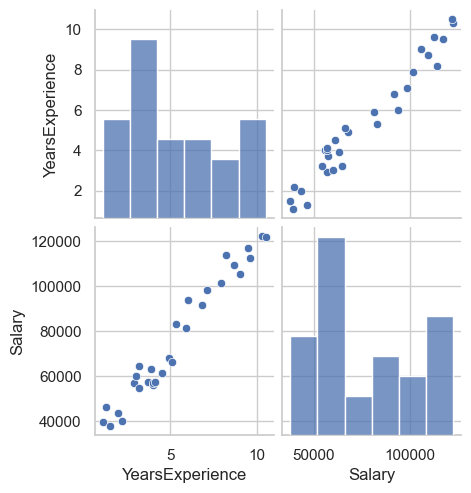

In [7]:
# 1. Trực quan hóa toàn bộ tập dữ liệu bằng Seaborn Pairplot
sns.pairplot(dataset)
plt.show()


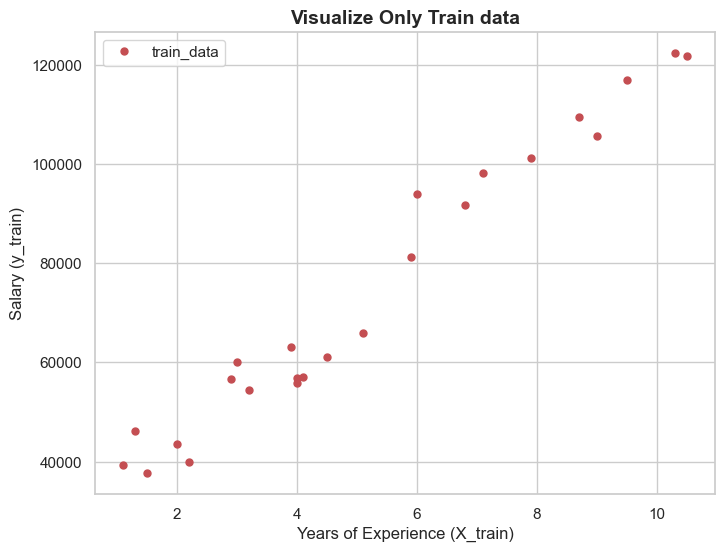

In [8]:
# 2. Trực quan hóa riêng tập huấn luyện (Visualize Only Train data)
plt.figure(figsize=(8, 6))
plt.plot(X_train, y_train, 'r.', markersize=10, label='train_data')
plt.xlabel('Years of Experience (X_train)', fontsize=12)
plt.ylabel('Salary (y_train)', fontsize=12)
plt.title('Visualize Only Train data', fontsize=14, fontweight='bold')
plt.legend(loc='upper left')
plt.show()


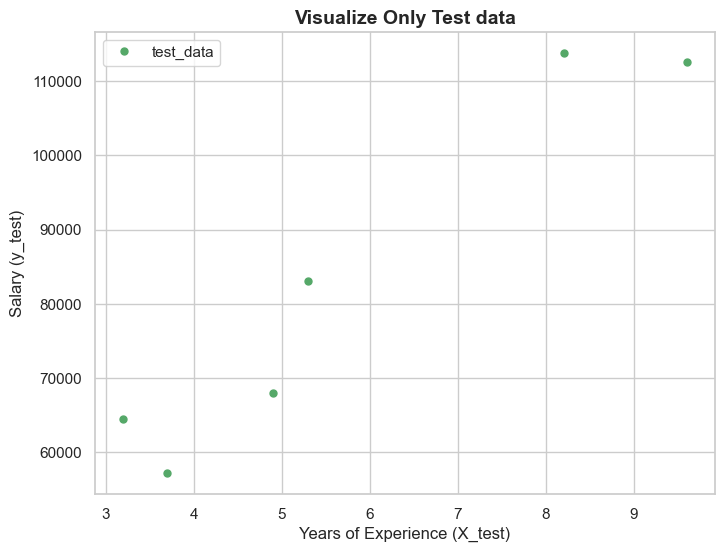

In [9]:
# 3. Trực quan hóa riêng tập kiểm thử (Visualize Only Test data)
plt.figure(figsize=(8, 6))
plt.plot(X_test, y_test, 'g.', markersize=10, label='test_data')
plt.xlabel('Years of Experience (X_test)', fontsize=12)
plt.ylabel('Salary (y_test)', fontsize=12)
plt.title('Visualize Only Test data', fontsize=14, fontweight='bold')
plt.legend(loc='upper left')
plt.show()


**Nhận xét:**
* Ba biểu đồ trên cho thấy rõ ràng rằng dữ liệu có mối quan hệ tương quan tuyến tính rất mạnh và rõ rệt giữa số năm kinh nghiệm (`YearsExperience`) và mức lương (`Salary`). 
* Điểm dữ liệu phân bố dọc theo một xu hướng thẳng tăng dần đều (*linearly correlated*). Do đó, việc áp dụng mô hình **Hồi quy tuyến tính (Linear Regression)** là hoàn toàn phù hợp và tối ưu!


---
## 0.6 BƯỚC 3: HUẤN LUYỆN MÔ HÌNH HỒI QUY TUYẾN TÍNH ĐƠN GIẢN
*(STEP 3: TRAINING SIMPLE LINEAR REGRESSION MODEL)*


In [10]:
# 1. Khởi tạo và huấn luyện mô hình hồi quy tuyến tính trên tập Train
from sklearn.linear_model import LinearRegression

regressor = LinearRegression()
regressor.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [11]:
# 2. Xuất các hệ số hồi quy đã học được
b0 = regressor.intercept_
b1 = regressor.coef_[0]

print(f"Hệ số chặn (Intercept b0) : {b0:.4f}")
print(f"Hệ số góc   (Slope b1)     : {b1:.4f}")
print(f"--> Phương trình hồi quy : Salary = {b0:.2f} + {b1:.2f} * YearsExperience")


Hệ số chặn (Intercept b0) : 25321.5830
Hệ số góc   (Slope b1)     : 9423.8153
--> Phương trình hồi quy : Salary = 25321.58 + 9423.82 * YearsExperience


### 0.6.1 Dự đoán kết quả trên tập kiểm thử (Predicting the Test set results)

In [12]:
# 1. Thực hiện dự đoán trên tập Test
y_pred = regressor.predict(X_test).round(1)

# 2. Lập bảng so sánh giữa Lương thực tế (Original Salary) và Lương dự đoán (Predict Salary)
calculation = pd.DataFrame(np.c_[y_test, y_pred], columns=["Original Salary", "Predict Salary"])
calculation


,Original Salary,Predict Salary
0,112635.0,115790.2
1,67938.0,71498.3
2,113812.0,102596.9
3,83088.0,75267.8
4,64445.0,55477.8
5,57189.0,60189.7


In [13]:
# 3. Đánh giá độ chính xác (R^2 Score) trên tập Train và tập Test
print("Training Accuracy :", regressor.score(X_train, y_train))
print("Testing Accuracy  :", regressor.score(X_test, y_test))


Training Accuracy : 0.9645401573418146
Testing Accuracy  : 0.9024461774180497


---
## 0.7 TRỰC QUAN HÓA KẾT QUẢ TRÊN TẬP HUẤN LUYỆN
*(VISUALISING THE TRAINING SET RESULTS)*


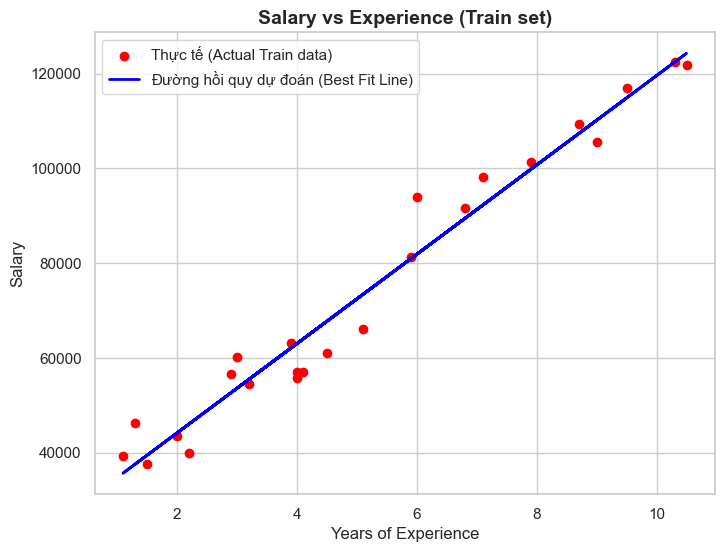

In [14]:
plt.figure(figsize=(8, 6))
plt.scatter(X_train, y_train, color='red', label='Thực tế (Actual Train data)')
plt.plot(X_train, regressor.predict(X_train), color='blue', linewidth=2, label='Đường hồi quy dự đoán (Best Fit Line)')
plt.title('Salary vs Experience (Train set)', fontsize=14, fontweight='bold')
plt.xlabel('Years of Experience', fontsize=12)
plt.ylabel('Salary', fontsize=12)
plt.legend()
plt.show()


---
## 0.8 TRỰC QUAN HÓA KẾT QUẢ TRÊN TẬP KIỂM THỬ
*(VISUALISING THE TEST SET RESULTS)*


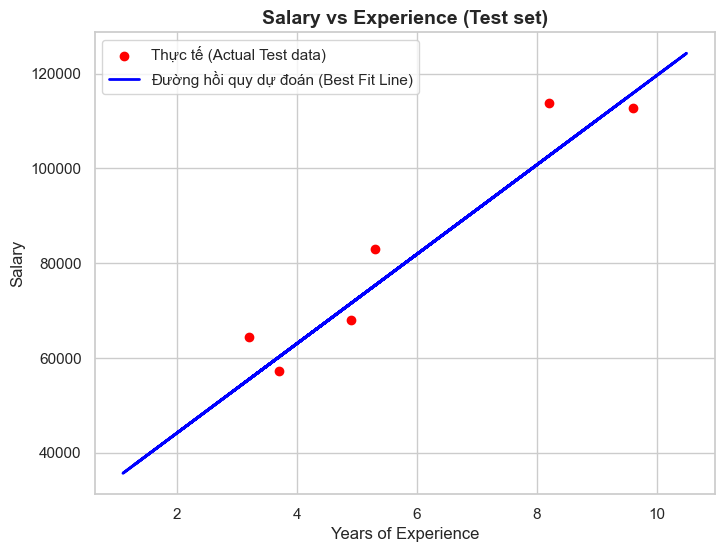

In [15]:
plt.figure(figsize=(8, 6))
plt.scatter(X_test, y_test, color='red', label='Thực tế (Actual Test data)')
plt.plot(X_train, regressor.predict(X_train), color='blue', linewidth=2, label='Đường hồi quy dự đoán (Best Fit Line)')
plt.title('Salary vs Experience (Test set)', fontsize=14, fontweight='bold')
plt.xlabel('Years of Experience', fontsize=12)
plt.ylabel('Salary', fontsize=12)
plt.legend()
plt.show()


---
## 0.9 PHẦN MỞ RỘNG: ĐÁNH GIÁ CHUYÊN SÂU & DỰ ĐOÁN THỰC TẾ
*(ADVANCED EVALUATION & PRACTICAL PREDICTIONS)*

Để đánh giá toàn diện mô hình hồi quy, chúng ta tính toán các chỉ số sai số phổ biến:
* **MAE (Mean Absolute Error):** Sai số tuyệt đối trung bình.
* **MSE (Mean Squared Error):** Sai số bình phương trung bình.
* **RMSE (Root Mean Squared Error):** Căn bậc hai của sai số bình phương trung bình.
* **$R^2$ Score (Coefficient of Determination):** Tỉ lệ phương sai được giải thích bởi mô hình.


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

metrics_df = pd.DataFrame({
    "Chỉ số đánh giá": ["MAE (Sai số tuyệt đối TB)", "MSE (Sai số bình phương TB)", "RMSE (Căn bậc hai MSE)", "R² Score (Độ phù hợp)"],
    "Giá trị": [f"{mae:,.2f}", f"{mse:,.2f}", f"{rmse:,.2f}", f"{r2:.4f}"]
})
metrics_df


,Chỉ số đánh giá,Giá trị
0,MAE (Sai số tuyệt đối TB),"6,286.45"
1,MSE (Sai số bình phương TB),"49,829,982.59"
2,RMSE (Căn bậc hai MSE),"7,059.04"
3,R² Score (Độ phù hợp),0.9024


### Dự đoán mức lương cho nhân viên có số năm kinh nghiệm mới:
Ví dụ dự đoán mức lương cho nhân viên có **5 năm**, **10 năm**, và **12 năm** kinh nghiệm:


In [17]:
years_new = pd.DataFrame({"YearsExperience": [5.0, 10.0, 12.0]})
predicted_salaries = regressor.predict(years_new)

for yr, sal in zip(years_new["YearsExperience"], predicted_salaries):
    print(f"Kinh nghiệm: {yr:4.1f} năm  -->  Lương dự đoán: ${sal:,.2f}")


Kinh nghiệm:  5.0 năm  -->  Lương dự đoán: $72,440.66
Kinh nghiệm: 10.0 năm  -->  Lương dự đoán: $119,559.74
Kinh nghiệm: 12.0 năm  -->  Lương dự đoán: $138,407.37


---
## ❖ KẾT LUẬN VÀ TỔNG KẾT BÀI LAB

1. **Hiệu năng mô hình:**
   * Mô hình Hồi quy tuyến tính đơn giản đạt hệ số $R^2$ trên tập Train xấp xỉ **96.45%** và trên tập Test đạt xấp xỉ **90.24%**.
   * Điều này chứng minh mối quan hệ giữa Số năm kinh nghiệm và Mức lương mang tính chất tuyến tính rất cao, mô hình tổng quát hóa tốt và không bị hiện tượng quá khớp (overfitting).
2. **Ý nghĩa thực tiễn:**
   * Hệ số góc $b_1 pprox 9423.82$ phản ánh rằng trung bình mỗi năm kinh nghiệm tăng thêm, mức lương của nhân viên sẽ tăng thêm khoảng **$9,423.82**.
   * Hệ số chặn $b_0 pprox 25321.58$ thể hiện mức lương xuất phát điểm cơ sở cho người chưa có kinh nghiệm (0 năm).
3. **Môi trường thực thi:**
   * Notebook tương thích hoàn toàn khi chạy offline trên máy tính và trực tuyến trên **Google Colab** thông qua nút bấm liên kết trực tiếp với GitHub.
